**Random forest figure**

In [1]:
import matplotlib.font_manager as fm
import matplotlib as mpl

font_path = r"C:\Users\LENOVO\AppData\Local\Microsoft\Windows\Fonts\HELVETICA.TTF"
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

font_name

'Helvetica'

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 30}
Best CV R²: 0.7297138957774052

Random Forest Regression Test Performance:
-------------------------------------------
R²:   0.8074
MAE:  0.0327
MSE:  0.0031
RMSE: 0.0556


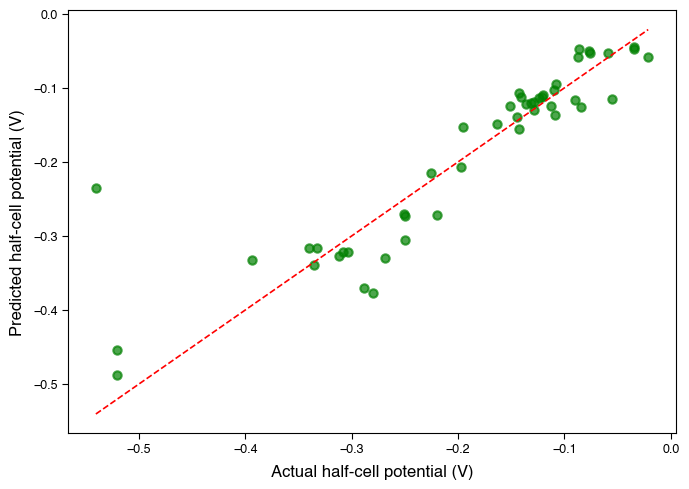

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('data.csv')
df.dropna(inplace=True)
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ======================
# 2. Scaling
# ======================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 3. Random Forest + GridSearchCV
# ======================
rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [30, 50, 70],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    verbose=1
)

grid_search.fit(X_train, y_train)

# ======================
# 4. Best model
# ======================
best_rf = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

# ======================
# 5. Predictions
# ======================
y_pred = best_rf.predict(X_test)

# ======================
# 6. Evaluation
# ======================
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\nRandom Forest Regression Test Performance:")
print("-------------------------------------------")
print(f"R²:   {r2:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

# ======================
# 7. Q1 Journal Plot
# ======================

# ── Helvetica Light font ──────────────────────────────────────────
font_path = r"C:\Users\LENOVO\AppData\Local\Microsoft\Windows\Fonts\HELVETICA.TTF"
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

mpl.rcParams['font.family'] = font_name
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter plot
ax.scatter(y_test, y_pred,
        #    color='#2d6a2d',
        #    edgecolors='#1a4d1a',
        color='green',
           alpha=0.7,
           linewidths=1.5
           )
        #    s=40,
        #    linewidths=0.5)

# 1:1 reference line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=1.2, label='1:1 line')



# Axis labels
ax.set_xlabel('Actual half-cell potential (V)', fontsize=12, labelpad=6)
ax.set_ylabel('Predicted half-cell potential (V)', fontsize=12, labelpad=6)

# Ticks
ax.tick_params(axis='both', labelsize=9, direction='out', length=4, width=0.8)

# Rectangular box — all 4 spines visible
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

# White background
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.tight_layout()
# plt.savefig('rf_predicted_vs_actual.svg', dpi=1000, bbox_inches='tight', format='svg')
plt.savefig('rf_predicted_vs_actual.pdf', dpi=1000, bbox_inches='tight', format='pdf')
plt.show()

**KNN**

Fitting 5 folds for each of 80 candidates, totalling 400 fits
Best parameters: {'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best CV R²: 0.707035759283879

KNN Regression Test Performance:
-------------------------------
R²: 0.831022140463288
MAE: 0.031020446762548948
MSE: 0.0027143727949454316
RMSE: 0.052099642944510006


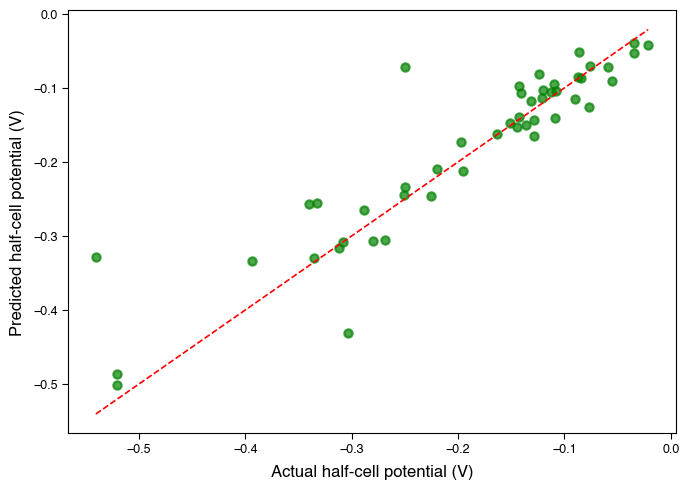

In [18]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 3. KNN Regressor + GridSearchCV
# ======================
knn = KNeighborsRegressor()

param_grid = {
    'n_neighbors': list(range(1, 21)),  # Test k from 1 to 20
    'weights': ['uniform', 'distance'],  # uniform or distance-weighted
    'p': [1, 2]  # p=1 -> Manhattan, p=2 -> Euclidean
}

grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    verbose=1
)

grid_search.fit(X_train, y_train)

# ======================
# 4. Best model & parameters
# ======================
best_knn = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

# ======================
# 5. Predictions on test set
# ======================
y_pred = best_knn.predict(X_test)

# ======================
# 6. Evaluation
# ======================
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\nKNN Regression Test Performance:")
print("-------------------------------")
print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

# ======================
# 7. Q1 Journal Plot
# ======================

# ── Helvetica Light font ──────────────────────────────────────────
font_path = r"C:\Users\LENOVO\AppData\Local\Microsoft\Windows\Fonts\HELVETICA.TTF"
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

mpl.rcParams['font.family'] = font_name
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter plot
ax.scatter(y_test, y_pred,
        #    color='#2d6a2d',
        #    edgecolors='#1a4d1a',
        color='green',
           alpha=0.7,
           linewidths=1.5
           )
        #    s=40,
        #    linewidths=0.5)

# 1:1 reference line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=1.2, label='1:1 line')



# Axis labels
ax.set_xlabel('Actual half-cell potential (V)', fontsize=12, labelpad=6)
ax.set_ylabel('Predicted half-cell potential (V)', fontsize=12, labelpad=6)

# Ticks
ax.tick_params(axis='both', labelsize=9, direction='out', length=4, width=0.8)

# Rectangular box — all 4 spines visible
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

# White background
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.tight_layout()
# plt.savefig('rf_predicted_vs_actual.svg', dpi=1000, bbox_inches='tight', format='svg')
plt.savefig('knn_predicted_vs_actual.pdf', dpi=1000, bbox_inches='tight', format='pdf')
plt.show()

**Linear regression**

R² score: 0.6748509328395049
Mean Absolute Error (MAE): 0.053666317330573886
Mean Squared Error (MSE): 0.00522302616817433
Root Mean Squared Error (RMSE): 0.07227050690409145


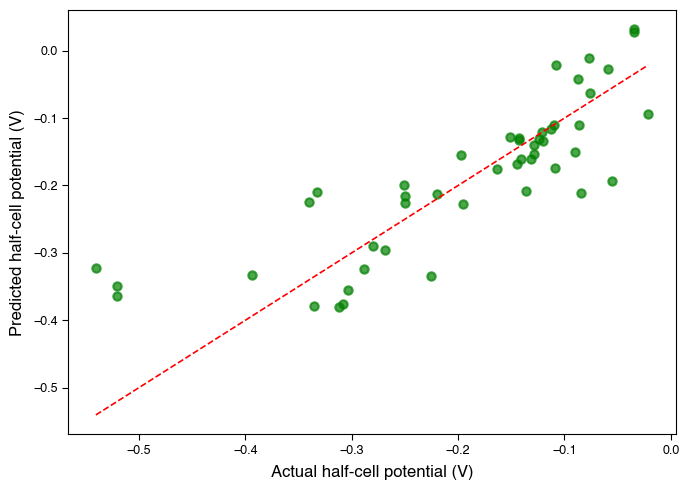

In [21]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']
# Import libraries
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)
# Predictions
y_pred = model.predict(X_test)

# 1. R² score
r2 = model.score(X_test, y_test)
print("R² score:", r2)

# 2. Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

# 3. Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

# 4. Root Mean Squared Error
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

# ======================
# 7. Q1 Journal Plot
# ======================

# ── Helvetica Light font ──────────────────────────────────────────
font_path = r"C:\Users\LENOVO\AppData\Local\Microsoft\Windows\Fonts\HELVETICA.TTF"
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

mpl.rcParams['font.family'] = font_name
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter plot
ax.scatter(y_test, y_pred,
        #    color='#2d6a2d',
        #    edgecolors='#1a4d1a',
        color='green',
           alpha=0.7,
           linewidths=1.5
           )
        #    s=40,
        #    linewidths=0.5)

# 1:1 reference line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=1.2, label='1:1 line')



# Axis labels
ax.set_xlabel('Actual half-cell potential (V)', fontsize=12, labelpad=6)
ax.set_ylabel('Predicted half-cell potential (V)', fontsize=12, labelpad=6)

# Ticks
ax.tick_params(axis='both', labelsize=9, direction='out', length=4, width=0.8)

# Rectangular box — all 4 spines visible
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

# White background
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.tight_layout()
# plt.savefig('rf_predicted_vs_actual.svg', dpi=1000, bbox_inches='tight', format='svg')
plt.savefig('linear_predicted_vs_actual.pdf', dpi=1000, bbox_inches='tight', format='pdf')
plt.show()

**SVR**

SVR Performance:
----------------
R² score: 0.7865143684229426
Mean Absolute Error (MAE): 0.03893005603351316
Mean Squared Error (MSE): 0.0034293225873097927
Root Mean Squared Error (RMSE): 0.05856041826447103


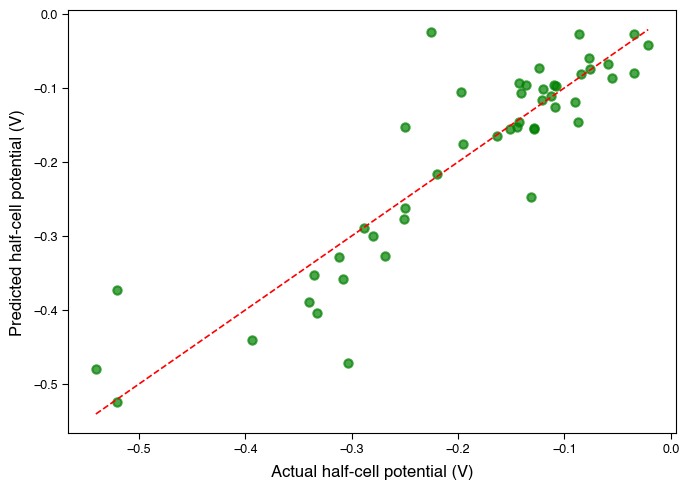

In [19]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ======================
# 3. Scale features
# ======================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 4. Train SVR model
# ======================
# You can try kernel='linear' or kernel='rbf'
svr_model = SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.01)
svr_model.fit(X_train, y_train)

# ======================
# 5. Predictions
# ======================
y_pred = svr_model.predict(X_test)

# ======================
# 6. Evaluation
# ======================
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("SVR Performance:")
print("----------------")
print("R² score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

# ======================
# 7. Q1 Journal Plot
# ======================

# ── Helvetica Light font ──────────────────────────────────────────
font_path = r"C:\Users\LENOVO\AppData\Local\Microsoft\Windows\Fonts\HELVETICA.TTF"
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

mpl.rcParams['font.family'] = font_name
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter plot
ax.scatter(y_test, y_pred,
        #    color='#2d6a2d',
        #    edgecolors='#1a4d1a',
        color='green',
           alpha=0.7,
           linewidths=1.5
           )
        #    s=40,
        #    linewidths=0.5)

# 1:1 reference line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=1.2, label='1:1 line')



# Axis labels
ax.set_xlabel('Actual half-cell potential (V)', fontsize=12, labelpad=6)
ax.set_ylabel('Predicted half-cell potential (V)', fontsize=12, labelpad=6)

# Ticks
ax.tick_params(axis='both', labelsize=9, direction='out', length=4, width=0.8)

# Rectangular box — all 4 spines visible
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

# White background
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.tight_layout()
# plt.savefig('rf_predicted_vs_actual.svg', dpi=1000, bbox_inches='tight', format='svg')
plt.savefig('svr_predicted_vs_actual.pdf', dpi=1000, bbox_inches='tight', format='pdf')
plt.show()

**Bayesian Ridge Regression**

Bayesian Ridge Regression Performance:
R²: 0.6752152891638793
MAE: 0.053377684063800925
MSE: 0.005217173336937979
RMSE: 0.07223000302462944


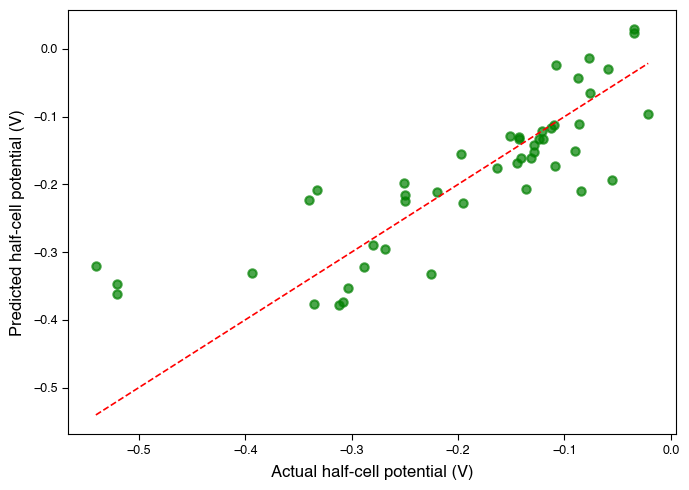

In [20]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train Bayesian Ridge Regression
model = BayesianRidge()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Bayesian Ridge Regression Performance:")
print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

# ======================
# 7. Q1 Journal Plot
# ======================

# ── Helvetica Light font ──────────────────────────────────────────
font_path = r"C:\Users\LENOVO\AppData\Local\Microsoft\Windows\Fonts\HELVETICA.TTF"
fm.fontManager.addfont(font_path)
prop = fm.FontProperties(fname=font_path)
font_name = prop.get_name()

mpl.rcParams['font.family'] = font_name
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter plot
ax.scatter(y_test, y_pred,
        #    color='#2d6a2d',
        #    edgecolors='#1a4d1a',
        color='green',
           alpha=0.7,
           linewidths=1.5
           )
        #    s=40,
        #    linewidths=0.5)

# 1:1 reference line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=1.2, label='1:1 line')



# Axis labels
ax.set_xlabel('Actual half-cell potential (V)', fontsize=12, labelpad=6)
ax.set_ylabel('Predicted half-cell potential (V)', fontsize=12, labelpad=6)

# Ticks
ax.tick_params(axis='both', labelsize=9, direction='out', length=4, width=0.8)

# Rectangular box — all 4 spines visible
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

# White background
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.tight_layout()
# plt.savefig('rf_predicted_vs_actual.svg', dpi=1000, bbox_inches='tight', format='svg')
plt.savefig('Bayesian_predicted_vs_actual.pdf', dpi=1000, bbox_inches='tight', format='pdf')
plt.show()

**correlation matrix**

                       temperature_c  humidity_%  half-cell_potential_v  \
temperature_c               1.000000    0.304465              -0.599430   
humidity_%                  0.304465    1.000000              -0.400347   
half-cell_potential_v      -0.599430   -0.400347               1.000000   
surface_resistivity        -0.423757   -0.197571               0.681702   
surface_roughness           0.178015   -0.136131              -0.156344   

                       surface_resistivity  surface_roughness  
temperature_c                    -0.423757           0.178015  
humidity_%                       -0.197571          -0.136131  
half-cell_potential_v             0.681702          -0.156344  
surface_resistivity               1.000000           0.017438  
surface_roughness                 0.017438           1.000000  


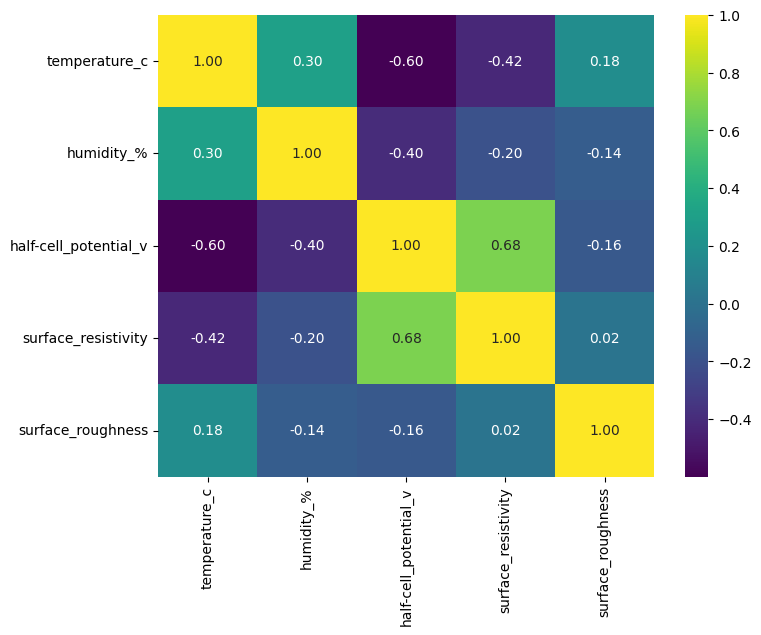

In [20]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)

import seaborn as sns
import matplotlib.pyplot as plt
corr = df.corr()

# 2. Print correlation matrix
print(corr)

# 3. Visualize it
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis")
plt.title("")
plt.savefig("correlation_matrix_graph.pdf", dpi=1000, bbox_inches='tight')
plt.show()

**SHAP feature importance**

In [1]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 3. KNN Regressor + GridSearchCV
# ======================
knn = KNeighborsRegressor()

param_grid = {
    'n_neighbors': list(range(1, 21)),  # Test k from 1 to 20
    'weights': ['uniform', 'distance'],  # uniform or distance-weighted
    'p': [1, 2]  # p=1 -> Manhattan, p=2 -> Euclidean
}

grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    verbose=1
)

grid_search.fit(X_train, y_train)

# ======================
# 4. Best model & parameters
# ======================
best_knn = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

# ======================
# 5. Predictions on test set
# ======================
y_pred = best_knn.predict(X_test)

import shap
import matplotlib.pyplot as plt

# Correct explainer for KNN
explainer = shap.KernelExplainer(best_knn.predict, X_train)

# SHAP values for test set
shap_values = explainer.shap_values(X_test)

Fitting 5 folds for each of 80 candidates, totalling 400 fits
Best parameters: {'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best CV R²: 0.707035759283879


d:\Python\virtual_environment\main_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using 189 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
100%|██████████| 48/48 [00:00<00:00, 169.08it/s]


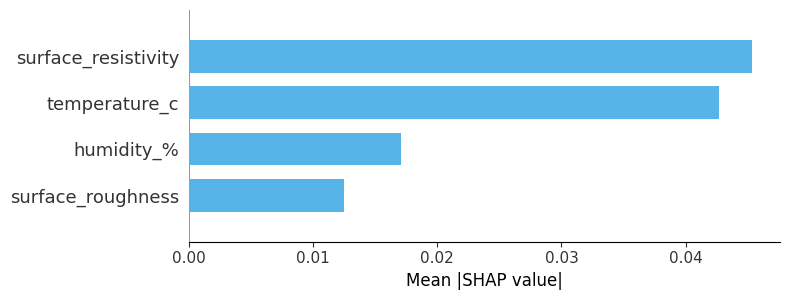

In [2]:
shap.summary_plot(shap_values,
                   X_test, plot_type="bar",
                     show=False,
                       color="#56B4E9",
                       feature_names=X.columns)
plt.title("")
plt.xlabel("Mean |SHAP value|", fontsize=12)
plt.tight_layout()
plt.savefig("shap_feature_importance.svg", dpi=1000, bbox_inches='tight')
plt.show()
# color="#f23a78",